# Group comparison: reproducible development figures

This notebook plots A and B's validation accuracy on the same seed-42 nested training rows, and B's training and validation log loss. These figures are developmental.

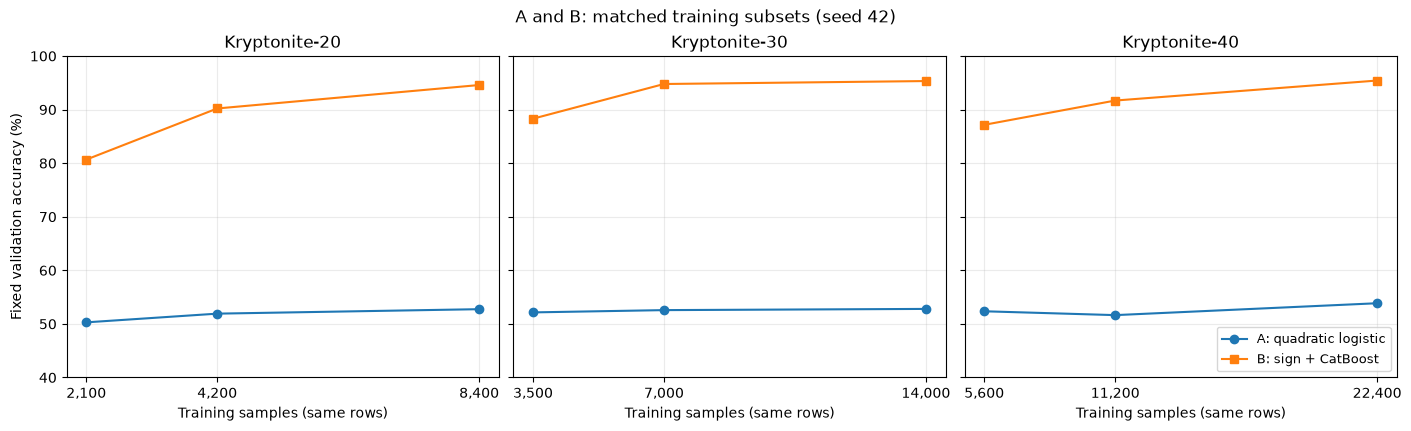

In [1]:
from pathlib import Path
import csv, json
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if not (root / 'common.py').exists():
    root = next(p for p in root.parents if (p / 'common.py').exists())
figures = root / 'docs' / 'figures'
figures.mkdir(parents=True, exist_ok=True)

with (root / 'results/baseline_runs.csv').open(encoding='utf-8', newline='') as f:
    baseline = list(csv.DictReader(f))
with (root / 'B_Traditional_ML/results/aligned_a_subsets/results.csv').open(encoding='utf-8', newline='') as f:
    catboost = list(csv.DictReader(f))

assert len(catboost) == 9
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True, constrained_layout=True)
for ax, dataset in zip(axes, ['20', '30', '40']):
    a = sorted([r for r in baseline if r['dataset'] == dataset and r['method'] == 'quadratic-logistic'], key=lambda r: int(r['training_percent']))
    b = sorted([r for r in catboost if r['dataset'] == dataset], key=lambda r: int(r['training_percent']))
    assert [r['training_percent'] for r in a] == [r['training_percent'] for r in b] == ['25', '50', '100']
    assert [r['training_size'] for r in a] == [r['n_train'] for r in b]
    sizes = [int(r['training_size']) for r in a]
    ax.plot(sizes, [100*float(r['validation_accuracy']) for r in a], marker='o', label='A: quadratic logistic')
    ax.plot(sizes, [100*float(r['validation_accuracy']) for r in b], marker='s', label='B: sign + CatBoost')
    ax.set_title('Kryptonite-' + dataset)
    ax.set_xlabel('Training samples (same rows)')
    ax.set_xticks(sizes, [f'{v:,}' for v in sizes])
    ax.grid(alpha=.25)
    ax.set_ylim(40, 100)
axes[0].set_ylabel('Fixed validation accuracy (%)')
axes[-1].legend(loc='lower right', fontsize=9)
fig.suptitle('A and B: matched training subsets (seed 42)')
fig.savefig(figures / 'matched_a_b_accuracy.png', dpi=180, bbox_inches='tight')
fig.savefig(figures / 'matched_a_b_accuracy.pdf', bbox_inches='tight')
plt.show()

Each point is one stratified nested subset (seed 42), with each model evaluated on the same fixed validation set. The 100% B points are verified against B's prior full-training predictions. These are development comparisons, not independent final test results.

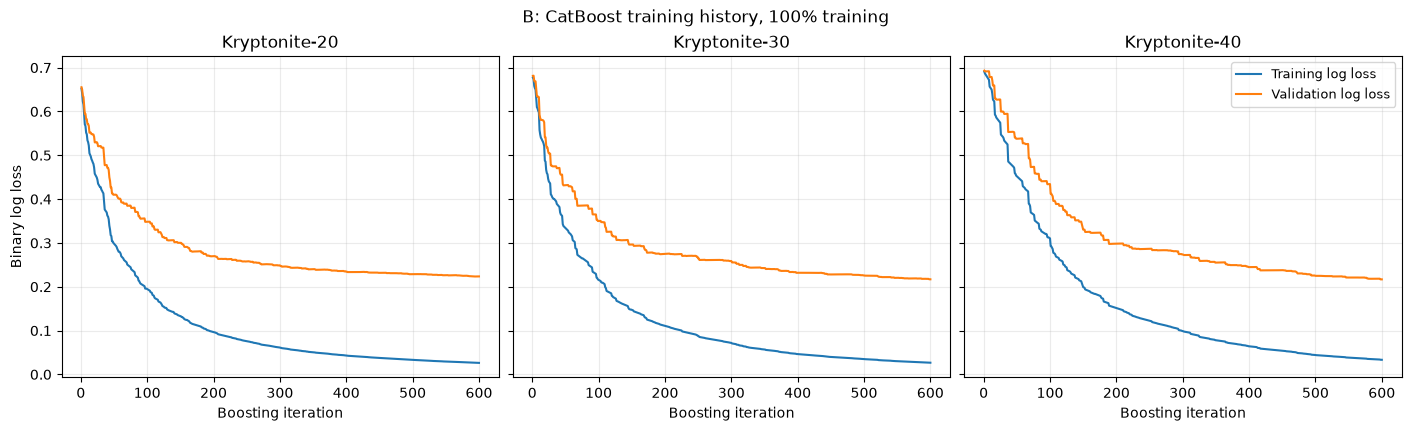

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True, constrained_layout=True)
for ax, dataset in zip(axes, ['20', '30', '40']):
    run = json.loads((root / f'B_Traditional_ML/results/training_loss_curves/{dataset}.json').read_text(encoding='utf-8'))
    assert len(run['train_logloss']) == len(run['validation_logloss']) == 600
    iterations = range(1, 601)
    ax.plot(iterations, run['train_logloss'], label='Training log loss')
    ax.plot(iterations, run['validation_logloss'], label='Validation log loss')
    ax.set_title('Kryptonite-' + dataset)
    ax.set_xlabel('Boosting iteration')
    ax.grid(alpha=.25)
axes[0].set_ylabel('Binary log loss')
axes[-1].legend(fontsize=9)
fig.suptitle('B: CatBoost training history, 100% training')
fig.savefig(figures / 'catboost_train_validation_loss.png', dpi=180, bbox_inches='tight')
fig.savefig(figures / 'catboost_train_validation_loss.pdf', bbox_inches='tight')
plt.show()

B's models were retrained with `eval_set` only to record the histories, with best-model selection disabled and no early stopping. Final validation probabilities and predictions exactly reproduce the earlier 100% training results. Training loss is CatBoost's recorded training metric; validation loss is computed on the fixed development validation set.